In [ ]:
RUN_EE = True
EE_PROJECT_ID = 'ee-butarbutarernie'

# Biarkan kosong sementara sampai CRS peta gambut terverifikasi
PEAT_ASSET_ID = ''

RUN_LANDSAT_VIIRS_STRATA = True
RUN_DEPTH_LULC_CROSSTAB = True

STRATA_PAIR_MONTHS = list(range(5, 11))
CROSS_PAIR_MONTHS = [9]

In [ ]:
from pathlib import Path
import io, json, calendar, warnings, hashlib, zipfile, base64
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# OPTIONAL: specify a folder containing data/ and the three original CSVs.
# Leave both blank for automatic setup. If no package exists, archived
# byte-for-byte CSVs embedded below are restored automatically.
PACKAGE_ROOT = ''  # Example: '/content/drive/MyDrive/CKPP_v23_Analysis_20261114'
PACKAGE_ZIP_PATH = ''  # Example: '/content/drive/MyDrive/CKPP_v23_Analysis_20261114_Package.zip'
EXPECTED_SHA256 = {'PulangPisau_2026_MayOct_dNBR_VIIRS_Exploratory_Overlap_v22.csv': 'c36caeb9ecdfd29ae3f1fd2ffda315a1bff93a1d212e968656d5139a6a10f637', 'Kalteng_2026_AprOct_7_Monthly_Sentinel2_QC_v07.csv': '91290abdeaa94ce7593e8f329097d896ab53e1a362b3cc144b6fb416c2b6a19d', 'Atribut_Gambut_Kalimantan_Audit_20261114.csv': '9b872606fac908ef40bdfc37d64d51426fb67b538dfeeaa25eb21670e80a0a31'}
CSV_FILENAMES = list(EXPECTED_SHA256)
ORIGINAL_ARCHIVED_CSV_ZIP_BASE64 = '''
UEsDBBQAAAAIAANubl0oSwRH1QMAAOYIAAA+AAAAUHVsYW5nUGlzYXVfMjAyNl9NYXlPY3RfZE5CUl9WSUlSU19FeHBsb3JhdG9yeV9PdmVybGFwX3YyMi5j
c3bFVMFu3DYQvfcrFjlzCc6QnCGP6aFAAjQFnKJXQdbStgCtpEhat/v3fdTGhZu0PdYL7MIezgz53rw319Iu5jyN21Ozmbntl/2nnJoy9I/9/VCaad76rh2a
dilt89Q24s7mu8Pf++2pH5vnvl/WZp7WfuufS9OVYVhfata5dNuC3K4dT/2p3UpzGu+X5rE0bib3H2ndNHXdZVn68fHrDV9z525rpodXmX+9a3/sd3UvBbcm
f0+uCL552kt6OwwvQIfrP5Xdmp9LO94gtdu3TKyXeZ6W7VXOdNnW/lT+LXHtllLG+vIV15bmbG6Jj0t/asbp3I+g6Gy6aXxAl7FDRj+afm368VTmgp9xa9oK
v+2uTbuuZV3PiJl+3MoyL2Vrt34aTYs+1xV157I9TafmuSwr4j+wYzHRvJ+X48/t1eTgWS27rMo5+ogz62MMzseUkiilZKIPzjplzyGpSIoG/77+uiiqQUPi
mH3Mjm5Br0mjRpfJkw/ZHBHlEDMl1Zw4k4pPRpzxGg2Zn9phLebdp7tfD+WPeZiWdpuW6+H06ce7428fPtx9PnTT8Tb4yos5jNN2uL8sYzkd68gOz+1QZwyU
78wzc1OncY/BN1V6/UPfNV/aG34xwH78eBkNiTpJFq8X9gCRvCFS64KTmCVUKiQbJc8WlDCiTjIiweLtKSraUUjBa4WMw8AxhOxyYKQZb7P4EDUF4oxc2tMU
3ERUk7ick8hOjMPfzJIql9ElVt3DxBIEPVwQF7LG+CZ8qQFX4GswQTyBL0AXHBCxN4Ec2+STd96l7DB95hwyoLMCjXNQDepSzQHuzFpjBoQGTsrJV41EaAHM
28BK9dxlT8wJdOGqRNmJBu9T5kog7so5ghu0EgeCzc4U+qTATn1ySkHehKkEpobj+8ujgV92FqB3+Cp6NhJiUpvw6oAjFTKQG3mLycIsMBtUlNWjRpPkKhiA
NuwsxQxJQaopSKRgKFqXHEyLMoHnoppkM1OEmBhVkp3fhQYpqirBfzvPNQZng0eGIbVOS95GUNmAouPnMpvss1exCS7BE6EIw54gGTiCqjIUZiOcZLJCSlFh
LWWUcYoWKCAqDpAe+LYC75AqVpUgaLC1PIydYogUUWw4WJCVNGchB/PGyhKh3HsHFwti0NrOEsocpQgxYS++jZTIGRB0/KXbsH8Sloel4KqpsGcNJc/Z2Uiw
hBfyAt4ciUSLjULAg2UFVQgJATNAZ8ceCghslbGgKmUZ6ssIYd1h4VAgiiHjYzharDrVqjFkYPlUnqAhxg3gNglWe943HsYHv8K/OVGM9H8T9SdQSwMEFAAA
AAgAA25uXc8ccj8yAgAA2AQAADIAAABLYWx0ZW5nXzIwMjZfQXByT2N0XzdfTW9udGhseV9TZW50aW5lbDJfUUNfdjA3LmNzdp2Tu27bQBBF+3yFPmBNzPtR
xkiTxoWLtAStEA4BiTIk2Uj+PrN0nKQWSILL2eXuuXdmjqf1+qP9mqdze7h/HI/ztLaHL9++/hndP9L7aB1PT5f34dt0WL6P+9PbfJ6e5/Flfx0V4Ngu+3md
x+fztL4e5ks7z5fT4fW6nNZxPV3nduwnjYfpaT58kkZA1mAwCDMG1yRDZa2Qu0KKImaaeFSEA4NSAJgVjaXxgILknmgWmSTNYQBPNkYSBbFo5NY+v7ycTz+X
43Sddx1xV59vy7pfpsPusj/P87qsz7vjfD0v+43oDuQO8JP+h4fqwiqO7N5DXpx1cgYIcyF1voq5E6kBhBI1HIIjDJicVIiySQxcQk0DzZOo+Ixv4dPOZ3/5
0IRDVYCltt3sMyWJMpFAcjO07GMlI4gy27N+HhBI6xKrH8G9qQzoCcqlyrkgy4Gy/gY+63z+zz8N7y5FZRKRNj7BOsazJvB9FQcTooAqUkes/AppGWhpoZGK
zXKIwjWTjFJbmWC6ic87X3zwaQBoFRASbTt35IgUFk1VMwfc8otJnJX45LCQVm6VHtJykaOqMJv7ULOb3IiSEY3xJr7ofPnBV0xehS5OSZAqHVm090uVULlW
jJ2P2UBq3kGrk7TqTyWMgrUHAMibwBC9+kqJ18uz9ecGwOyACB+ElVng2koTtazrzMFQLdIbMcqLzlwkQehW/Vu9RH1VcVndRUOCvYORh9CSW7Q9787cEPwG
QoRO+BtQSwMEFAAAAAgAA25uXYUika3JGgAA2ZoAACwAAABBdHJpYnV0X0dhbWJ1dF9LYWxpbWFudGFuX0F1ZGl0XzIwMjYxMTE0LmNzds1d23IbR5J9V4T+
gY+zEaXaqsysW4RjIuSRPfb6GrZm95EBS7DFECVySWku37YP+0n7C3tOoQGKIgCB6AbEGetCSjroOp2VebIqK+v//ud/f/ryP776y/Nvn7lff37u/uvpsx9+
/pv7/umPz77+6Zcf3Jff/Pjtj8++c7989f23X33tvnv+Y+RPwp/U/e3XZ09j/1n6z4q/98PTX75zv76aXc5Pv5+//WP47dOr+cydz96+/P3i6s3pH1cX7y/d
y/nlu1enL85n19enL94MX745e/vBF7N/ns7/+eL8/fXZ3+f89uV89g7ffTe/OpudL/6pu744Oz+9vDp7M7v6l7vunzbDp52+mp1e4hNnV6d/+/E/v/rl26+/
/erZ6V9++fXxo+gwiNk5/sXbd7O37pfZP2YnX87PZ69nb/84+fX92z9mZyc/zPGw86uTP305e/H6+h+zN5f/5r56+3J2OXt7cnH1x+zt2Wv3bPZuduV+4lcX
1xfnJ7/O8Biv3RP8//n86ursxck3s8vzi2t++/rddf+DJ05TTrX5pKGVoEljcVK1VS1qviaxKjW7n969ml+drhh7//b6cv7i7Pez+cvTzo378eLd6dX88uLq
3fylc65/9ov1n9vhPfEH+PT4kTg5JAc33/hm/qZzsvbJPvzmK/zFJUsacgnmSw0txKrmYo0p5KzB81vSik7KUIf3xB/g7fGj5NJBGFoQ8gFj789/P3t5h6Ml
HcP3+t/6kKIYUrLqq4UYVaqU7CxXzVGqL61U/jbdmyQ+3Iu1z0FwT/Ql+ONH1dUPGfpy/np2ffL0/OwKox8I+n72ZvZpm1kysNFqbo1+k9GYiIrPUiynonhG
lwpmWsm+JM2YZ3J/PoZHe7H2QQDvib+Cf/youfYhJc/ml1fz6zOQ8v7v8Fj/3o3o+/lvs9dTOROJeBsehqs1as5WXJPYYsjmmwXJOcdJZwrRPeEHdHjTAFuc
aNDL1/5k40um4Ve80hzgJWPWEsSZZrNqPqQgqcQ2pdVr9sReQmO44uJd19mHd/LzHLGJ7uFPz/Dz69n5VDEDxhXVh5D5jlPQAvdtpsGybwkeEvM/l2ljhpkn
/g08hq4O/60f+nPE+tkrfO84AQKPF7wEvJGmQQzMOLgk8oG5H+EMs9RJ+YAdEP4GHXQgLNlYOnax+KzWvElO0aQglqvDqDUnH9VKNDgAmdDkW/MEv8HGSJOL
t4JhHwVG9TWn+MWTH2ZXZ3u8+Q2R7+OX3//arQkRYY7iNYeMENigC6qLOVgSRKiaE37UOu3rB7wn/g08WCmYl+NZuRv87vKyLv7dpcVMEAtgnfgVM6LirdXW
xBCmmlR47JanDYCE98RfwoMUvIpbquD5/PLs5Lv3v81enfx19ua39+9O/pTCyYs3J09OvjiJgb+dykuKxRSrtwBNFFo2jF9KadIs+tA1EmTjs4s3c6QQV3/g
3aTw5As8An51/GWrARDJE2qJhLE2F9vkY72jD5dj36IO77Jh2rIIQqJFiH8pCWQgXCctcJwR/Ii2bVxs9g8dxhNngEEyEZyEAxGx3TVieBEPAzkiCcK9wE01
U0tRkocJMHbZfsMkjCfOEgbDjE5uZY7D2J5fXF78MX978vTs6uQ5YsDVCBMfGRchjlKo2UtMFlS1gA9Mz6wagm8UTZbd8Lynv0OmvfoHs+n7zISO5wm4wGMy
CTkiD5uYFKgYYmqIF8o8D3bcYLwYikiqoCWO5IV4noBLPPCiTvTAvHzKJ2LGI7n1rUK+xNISTDjBeyGDy75WCJk21iAWgJ6IC0BIRcw6sUON/GMPuc4gPpUs
wm0ohE6yXKyEWAKyxRA1RrCSmNLBv6UdiNnsQADnibeCQ8RABirpIdMiBo+KMAd2YBihYZ4YMr4k1QeruRVFBjCGFaB5wq3QQEp2+O9IpOwXTaGEkQ5JVgkt
KR4d8Q5xVfiGYfEQBcgJx9AiNBbgreBAS3FSHjYtmERVYvEthNoUZqIO4hNJatXiM9LmVG0ULR3NE25AAy3VST2YT51mJQp+FploahZqDaU1Js6gyGqKvmJI
SK1y28XrbhXfQPSEXCGCnOakHdZmtusxJAHQHz6VgGmS8VAut9xiqYiNSJtUdpIfWwyCaJ5wCzSEGg1OwyfG/PPsX7P3n098FLz7vuKfVJCk5EIRFVJETplj
tPRBCP7tavbi9dn1q3sqMk+0JRg4iU7jw+YEkpTLeEnAiCHewHILxHxARhlrRHph40ghmifcEg2siFM5MCufkGNZWoMYg3+oyWpQ6IGaEkWjry0a9FlM44YN
OE+8JRwCrKpTPdS4J4okyCm5v4CHhuvUmpODbJJaJCAuBoV2tU/yskWLFRIMsCUWSDGn9sBJKciymrdCPQaNnQ1TnURBd+TckMTkOoIUYnmCLbFASnKajkbK
fhtfSaNVRL6oUNiQTHB1oqalZfMQlK2YjDGVDuaJtgQDLdVpXbfS9/PserEbeMUljudnL2fnJ1+fz95dH0+BIfpDgIGMCNnVNLvYMHuKZG9SoFFtwqVhQnti
D9BBHj+y4CwcfDv9X5cbHKpJxtSOotXUmFi4iBSD4tyXGCDVre6/AbbmU4nuCb9EBwPRWTzKVvEq0N482PLVLB55jRS1HJBbgJ3MNSFERRc5bypCAyZ/a1rL
vhZy9yk6tCf2AA12BO/ogOw8Wc/HsPqBeKsQyTnkLhkT14ghmVPzyOWKJYk23eiJ7Qm+xEbsNXWmk+ySb3YYd59k03yJkoPAS7aYm/EdiaM44raBxFpCzNOa
A9JAgi+xkaGYObODVw30R7mdqq03EbysKB5qLJSau8tHKm4myGFEoE1VLdmITZO7DwJ4T/wVPI0kOUvTb6FvmhU15KReFBOCi6ExI1mwEGsIXiqCa0Qomc4I
iO0JvsRGQDUWqxygUGJjmEBWynWtiJAOn60RAT3FEiEbPFyhQJXLlFGC4J7oA3ikIyzOymEKBzYPGxmGj0w3IoZduWGVoLFD8qnVgABeUpk0OqbsCX+DjnFX
Z3WiqoHto1V4L/FaWFpnKXMzqPApIFpg5DC8kPKUowW4735jCY7BNmdtwpqATVM4N2p3Lju2XJBEF9e4zh+4Sot8gasv081ghFBi30A/fpS6kh67970tI9gU
1O7kA2LwKr6JBoEGTgWOpTS13CoUYOlLlDIdF4V6AtgraHARXYqf2P1c5Eg9XZLRyyxrTHGDoeQc4Pjg4nLVXhfmpKhABYgwMCODCrd3xPGcT77AE/YkST5Y
a1jzmR3KE2uAol2ISzI9F1Non5ZBRfONxQrMorNrjf65cFG2ISLjJW6lYvP8II4n0AIHNCjS1MPTsEc+kBQ0iE+CCVNZy+SYy0AQ1lp8CeXjsoDdWVjgeAJ1
HJbIQDslOxQPWx1kCVVz8Bn+Cr9BRsJUuQQYKVQOZFepxfYdaAfyRBqAMNDk0o4be1O4gnX2vzL2/uBrxT9mvnpYQMDExS/N4U1BmSFlS7UmhJG1mxL38QkE
9ERcAoKa7FI+HjV7eMmIaSA1+UpitAgSNjgL0NTMfEr41vptrPsQ0wE9EQdAEFNcKg+bmFSQHPqMZ1YxZPQuWoSazRiKJsTdZjKWmI7oCblEBDPVpXpoZrZr
SVEoCR7HwHMZlAWMpFQNUF0RqjZlpMljBw5AT8QlIMbdXGoHG/cE0QOs5Jh6jW2DJMysgEx4Z0GrhwTGnyXdiZfNzpV4noADHiZKDi6Ho9Gyj7ZQbXhepB65
Ig0QRTpvjWEHJgSBnmQcKR3NE26BBkqiy/HAlGyNrzEoZE/xXE7DoGEI0WAUEUbBIxjIs8caQsfjXmAe8DBqcVmOZghfn/22iyH8zr+2MgQoYe5/gxuqbKSh
Dl8b/kvqe1VYauN46XCeeAMcaFGX9UG7jWKFhXaBS4GSijr8UhEILcEDBm5ap3GsdDxPwAGPbsNctgftNkSjscAFWRoSktgQZrQmSNe+NZe5TpVHErPA8wTs
eIgygMwH1Kp3l2U/mkib1mVvTSSI7AZikFJAh/HMA+vzhDXHPrbcYPw7msy2tVhmQr2MeUBkLWvOyJp32wL9TKpMotbgocyyWEEKghQ+LpI5Ln5RW6qtKSK4
lzYBnifgEi+DmOJyedDEgBdMfGT4EFNVkPkhKcuq0pAIVrzfDIk5jhfCeeINcKSlulyPR8v6JbKPmLl7NERZ5cpdQKhtnpmx7KQ1npgyj1lVY7U2jhrC8YiU
DXDd0zSX28G4mSAwgYei3AoMAjMvrTiIfI2Fp/6iNA07GczmxUKAeaINYDCXElwJR6Nkrz3CBq3ZQkiQ9zxbzGidojbWYXJVh/tjY0gRnltr8QYMpERX4oFJ
2b5PzPXc6muAeoALEczpAFXLxQDPKsbc6pghdzBPtAVYoSGIK3I0Q9hHywpefkKy171GksLTDEhX8e2eBQv0Wxg1PTqaJ9yARlNQV/QhuwxFyC1QmtCxmCiJ
wZebyAkvOMN0WKdcxpBCNE+4JVoFKeaKPWynARHFogpok1RillRdRYQ05O+Q/WKNK80jWCGYJ9oSDKQkV9LxSNlna6rC7bMQvPZq6ByRtDdtgSx5qDdYTRzl
VgjWOV+AgZPsSj5aodp9zKNCq/ogkNoxWZGIMKOlwVbgSUILLU1ZdtK4rQ/sJTSIqQjGD7VGq/CYtWcLh1oDq3Ic/C4yvxS4Phjw/TRhOQagPbGX0DSb5kr7
XDVahuhYCsQF96RCqNBgElvVnHiOIOJx44Tbt4T2xF5Ay+NHNbgajlmLksE8tyGDmmFesPkMAmHzBjOAWEQsnLQko0ZP+BW6YsgRrulwjRx2z9iKVSgAgU3G
XKuGgjQiKzyE+VogP0Obkgpie4IP2CBCXJWj1KYw7YJTEkjpxpK7qo77cBRAqTLYQ3hOWoGEnJfoS3CelMFnVj1CcUq0xM1kHnEIUHUZYdpqaBCQnhVvsMY8
YXUKoD2xV9AYqLn6qW1nudEEetRt2BYhCXTxTpAs134iVwIPSAlUNvJEq7d2poWCQAcxoJ/IwmPyxFpB8bUnV9P0bEyhC3KDnMueaZflBtfsMovLGwKhD6ZJ
P6pGuEPFZm1EHE+gAYdmkV3NhydiDwWQA8/Ui+E5+76zZqdwERhDX+pPivR0TyKI4wm0xAEPxdVyeB72yjkxfrbwKGbCXXm2MAEhdGGwEh6PbfsS0YF8d4YL
ICRWlWnKoZjYXsAHaYq5ijBkUdm4xHG5BeqENQds16EfVWbdY6AdyBNpAMJAm6s77ixP4Rj3kAIVqp2LARCBObHDnMO8RaqEkXANCn8sa4+O3sc7EtETckAE
MS24Fh40MWxuxoYbbG/CAqZG3xCiLop5AgvUUxnLTEf0hFwgZjATEaoOxsxOMiIUVi8KvFazGJuTBFcQ+JCeJZ4qOw17y0ok4Xh4KC3gaA/imhx41ONcZGnV
gnBVRbKwJ5VrlSU5yroJ7vat71uxOy0dzhNvgAMr+BA9Giv7BFBuZbDnQEEmAZ2fuHqC/Apzx9i4q+o4ThZonnBEk4bkoZlrdjRS9pFXiKWRu6j4X1GesnYY
ALOtpmxtpHVHl7pZZRHOE2+AAyvJtfSgJ5DCkabipeLpedoTj8swbN0ZJNbTaxxHS4fzxFvACWjJruUHbSwIiSxvE6ikZLGE7CywykS489NLXutIx9LxPAEX
eJxDbIWw2yLuZwq/mEE1+VhalGrcx8uuL1dAl1im+ZS1R/bvFXwTPgCAKzxOowo//KCJqaHyXIilnDTlQp/L3TNMKip1DiTYSF44H4G3ggMtzbV2MFp2ESXK
g7NQSxxyQdh1hQlFKFCpCJm36rs2D3qz5+h5TigrMPbXXWwFHHbQ41wqBHtpPkOxQZ5xcmDaRC5BSEIyo0lCHUVLR/OEG9DYfjNExx/H4mWfw9fcgKiep27h
+jKmN3dCMHFCqp6HL1PNcRwvQPOEG9BICz4kyNFo2avuLWRlp9LIzVL6z+IkQsFBhwcvqUn5sLprD146mifcgMbuxdyqDXo8YvbZMeSRbOh4JD7sGscO7o0F
0f3kUg6RDW/H8NLBPNEGMNJijj8etL1IjoVbpsWQkrTGZqaL/RuMBukKHPG6bkH3mEdE40J8W6KRGCYR6QHupvaepL6qSGQ2zK5rwXKVikynsBm9TLhjBmhP
7BU0mcmOPzZuGH7Iz1H8rER2nIN1pIBZwy6XCmK4tFZ8YMOtKY/Ddmj2nykDNDtkswI+lM+1h6qJdfcNyR4suQZlo4vAw40GrUInmIpOeKSf2J7gS2wSUNl8
9kFsKtZSQIax1EBaqawChZ6C/ULGxwx5MulOG8EZasoSnGQ0xx/HbZW/4QhwrGz2wL5zPAWcm5Ma8e40IgPGiyw68cUBQPeEH9D7xQG8IyKGI2w9itTAfh4R
OUlDymYusbY7ZR6Ml9h0ymIC7tkQewXNkUaK1Q9Hens3QW8iaDpqzTi8d+rrV3glYlTowqsdWB7AOrYi4n7m7UovL97MGSyffJGGqJk+VSvOTrcEGnDIAoWu
TMrCNGVIubEMmkcieCwYkwG8QP1gWvicTSXluo2GLcfWCrs5KvsyLGDIAmsD9aAs7JeU2OK0q0LesG8rwocpvCaPdcKLCUxlLxIWMJ44CxjGBd6ScfuajMlJ
2CdjxZRl/8mUQuJ9HkVdipYilQTy2MT+x/uR0GE8cZYwJIHnR9MBSNi+VsHu+EiDirA5L63cUbAI644w6ZGQxpT3GmSH8cRZwnCQmRNstzXOz+UGmzXzBR6L
N9pkNh2NSEGRQHvurklo608V3ccfEpE3l6UlYg+APCBZHjQ38F1N2BzMePVBQA7Buu/Q5UPmyfgUy1huOqIn5IDIBJRXhsR6MG4mWRsPnMpe8NCJx3DBjRVk
RdqvDwiY2znvxM3mGUU8L/3WDuJ1o2lcfT4aMftsuxVudJiGzJqvwGsgLMDzm09wqvAPquNoIZ4n4BKPF3BBTEo4Gi17rYdm3rvia41wusUazy2zpWhky27e
EZHKOF46nCfeAEdeIhPhA/OyXX0nY+kmiwmMFw8x17DA7vCY9Ii4FkdaA9E84RZoHDSFrDxo58FSowBjKEERfljh5WIryqMBbJ3PLWUbOU06nifgEo/U9HOh
D9l9GLc5+oVVtfBgVOWRDgoUNhENyXgL2ThiCOeJt4QjL1Cku15O8pn8R+v3/VXeRArtxpo3aHK2V4JizeykONJ9EI1tQPOARlZ4W9aO52k+k0KJLJj2LVcu
8lljhsnG3qkXi+bEitc1q8D30SeA871keglHYjLbpj5sYqKwfVfiLWxZeXTEIfC0WNnbzIyNIlIdx0zH8wRc4pGawnvRDkbNJDsqUXmmxKvwQF2Ai8wOmqKf
XWxsPlHZQfzT1Gxp+gswT7QBjLxA0Uo9Hi/77CGwDwe3DnmOEQQVcdpqqRar8n7XJCmNoaWDsTuMLsDYWiEKBK20A/OyVaH0fZ5aE28HtFKM92TwUk/P1n0p
qcFMRg2b1Vb4kBUap4kGWuGDNge2ePBspQ53ypv9eFwuUrWYQMvyGPgYVmAJBFthkROI1V2vKNmDkyHobvWqq4i7cbEgZmPqi6gTCiSDIW5Cp/DwJrMdi+t6
JtxhpT/Ki7UfXNhACXgrOBLDltxyzPNosTdyQvrZkK/g7RdXewm28MJA3jecJz2FBXBP9AG83yvMi4W3LJSmGwMoxzyMwBbuYEErq5ASF8v6TdNahQ6D140X
+2D9LPHVl+G1l61ugjDsp1AGGJIAWap2UBL2keg8pySe1yso2/Ag4vMeo1DY/Dj2e9bLXhQsYDxxFjDUWgrhoumgHOzjHSF4WPWlvLAHcY3LHLwhma1CPBM5
iMW9OFjA+EXLEcJ0DqA3def78O7NxyR6kze/F5YQc02mb7Fye7E3QmDhOO/cWHvL10fEbFtFJR7v64wLPBLDXrXlQRPDvfCEp05dPwX48Vp5/2NClot0i2d6
RvJCPE/ABZ70kFHZ+uhgxEwiN5k1+IL0BAKrMdHkte3cn+hNh6HFsu1EzZaqDDFPwCUeiWms1zwaMXtVrrRkvQdKiiwkNa7hVU3I4rgwwrYrsY4jpuN5Ag54
NBkLPF5zNGb2az9Ti/oQ2AohivCmFmUfnRQaa594pVsdbTO5egIu8ahM+Qps58vzPoub4YFhSupszQrsJxfH/jlNMZ14syDPl6+9Ru4e/hd4noArPFIjvP/o
YNRMku9ntlcBN5DfygLTCrZCv5s0ewvZgrYdmNlSWQowT7QBjLQol0eOR8s++V1JqbELpCJaFy6rwi3wZtLWb4FWiWUMKx2M9Wd5ACMr0LNmR2Nln1ZOAXz4
zPyH23q1CuRu5R1W5o2XHyPbG8MKwTzRlmBkhUtz6ajtRnpnf4Gv4D2sUGxOSsjwnZgOPGCrrdqkXTZK8IRfoXfPkXkT2WZh/+ejBl3KSnZrDmq8+KAlZ2yD
z2vRISFS4yLQjZ7/cxle9LZ6CPxzSrw6/PPHj9TpFNWgJy/x+zdnb+dXs/NN73+wnJNneJarTxUIAv9i9t/v529vFtV5AQDSMHbPgKas/SaHkDT1i3ZbzXnS
AsGO7gk/oPMSQWfHJuub91tqKfGH5Ojy3RrCIKB4KSdXfIMyc3PcLGgYCsuvWXg4bUEl0T3hl+iPH2WXD0/XMvguCfvr+XzzRdhrTcuE+ym8Cxsi1zA74AMq
u7NGn0uLGaZXR9yttu5ObOPxhszO9At8tv5y5fhk3b3bdA1f/NatqchiXK+VQTTGAFWnPHMowbOiOTX20pmWL+WZAa5SL/F72Ym7XcC6e4DaytHCUdOK+NV6
X7Xeni5XIiZW3vWZasoNs6EfQ6hcnzWv2hovd6lTXncKcE/0FTjYwWfm+158tYftbLKc/sXdqSYswvNcHDAWt7Xm+BvjXQ1qKYd9fNI2w2HSSvglOuIdF0cn
ujp4BzvaRNZtAbCeLFMeJEQSGdhRcrF4xRKj3jKLN7SHPOIC4Q7miTaAQf8opnI5BjnTOCKrPNOQVZMhQLMfVa9sbrX1DUPeJPjpS8q3mc+i4Bp4SzhQ1Nzt
pZr7H7Y6sNnEDG3HTfbMpuKRx32kREH24EOu8M3W9rhfcIshleiJvgJXBDNWghxLKi199UoqbV6hWOql5aXD1s8DZx51jVmRRtXcBEkiCwPZ2ClOehEjwT3R
B3C4o/8HUEsBAhQDFAAAAAgAA25uXShLBEfVAwAA5ggAAD4AAAAAAAAAAAAAAIABAAAAAFB1bGFuZ1Bpc2F1XzIwMjZfTWF5T2N0X2ROQlJfVklJUlNfRXhw
bG9yYXRvcnlfT3ZlcmxhcF92MjIuY3N2UEsBAhQDFAAAAAgAA25uXc8ccj8yAgAA2AQAADIAAAAAAAAAAAAAAIABMQQAAEthbHRlbmdfMjAyNl9BcHJPY3Rf
N19Nb250aGx5X1NlbnRpbmVsMl9RQ192MDcuY3N2UEsBAhQDFAAAAAgAA25uXYUika3JGgAA2ZoAACwAAAAAAAAAAAAAAIABswYAAEF0cmlidXRfR2FtYnV0
X0thbGltYW50YW5fQXVkaXRfMjAyNjExMTQuY3N2UEsFBgAAAAADAAMAJgEAAMYhAAAAAA==
'''

def has_required_csvs(path):
    return all((path/'data'/name).is_file() for name in CSV_FILENAMES)

def verify_csvs(data_dir):
    for name, expected in EXPECTED_SHA256.items():
        p = data_dir/name
        if not p.is_file():
            raise FileNotFoundError(f'Missing required source CSV: {p}')
        actual = hashlib.sha256(p.read_bytes()).hexdigest()
        if actual != expected:
            raise ValueError(f'Source file differs from archived v22/v07 version: {p}\n'
                             f'Expected SHA256: {expected}\nActual SHA256: {actual}\n'
                             'Use an unmodified v23 package, or reconcile the newer dataset separately.')

def recover_from_zip(zip_path, destination):
    '''Extract only the three source CSVs; shapefile ZIP stays in original package.'''
    with zipfile.ZipFile(zip_path, 'r') as archive:
        lookup = {}
        for name in CSV_FILENAMES:
            matches = [n for n in archive.namelist()
                       if not n.endswith('/') and (n.endswith('/data/'+name) or n=='data/'+name)]
            if len(matches) != 1:
                raise ValueError(f'ZIP {zip_path} must contain exactly one data/{name}; found {len(matches)}')
            lookup[name] = archive.read(matches[0])
    for name, content in lookup.items():
        if hashlib.sha256(content).hexdigest() != EXPECTED_SHA256[name]:
            raise ValueError(f'ZIP CSV checksum mismatch for {name}; not writing data.')
    destination.mkdir(parents=True,exist_ok=True)
    for name,content in lookup.items():
        target=destination/name
        if target.exists() and hashlib.sha256(target.read_bytes()).hexdigest() != EXPECTED_SHA256[name]:
            raise ValueError(f'Refusing to overwrite changed source CSV: {target}')
        target.write_bytes(content)

session_root=Path('/content') if Path('/content').is_dir() else Path.cwd()
root_name='CKPP_v23_Analysis_20261114'
source_status=None
if PACKAGE_ROOT.strip():
    ROOT = Path(PACKAGE_ROOT).expanduser()
    if not has_required_csvs(ROOT):
        raise FileNotFoundError('PACKAGE_ROOT was explicitly selected but is incomplete: '+str(ROOT)
                            +'\nRemove PACKAGE_ROOT or select a folder with all 3 files under data/.')
    source_status='External folder selected manually'
else:
    CANDIDATES = [
        Path.cwd(), Path.cwd()/root_name,
        session_root, session_root/root_name,
        session_root/'drive/MyDrive'/root_name,
        session_root/'drive/MyDrive/Kalteng_Fire_2026_Journal_Research'/root_name,
    ]
    ROOT = next((p for p in CANDIDATES if has_required_csvs(p)), None)
    if ROOT is not None:
        source_status='Full external data/ folder auto-detected'
    else:
        ROOT=session_root/root_name
        zip_options=[Path(PACKAGE_ZIP_PATH).expanduser()] if PACKAGE_ZIP_PATH.strip() else [
            Path.cwd()/(root_name+'_Package.zip'),
            session_root/(root_name+'_Package.zip'),
            session_root/'drive/MyDrive'/(root_name+'_Package.zip'),
            Path.cwd()/'CKPP_v23_Colab_Ready_FIXED_20261114.zip',
            session_root/'CKPP_v23_Colab_Ready_FIXED_20261114.zip',
            session_root/'drive/MyDrive/CKPP_v23_Colab_Ready_FIXED_20261114.zip',
        ]
        package_zip=next((p for p in zip_options if p.is_file()), None)
        if package_zip is not None:
            recover_from_zip(package_zip, ROOT/'data')
            source_status='Three original CSVs recovered from package ZIP: '+str(package_zip)
        else:
            # This is NOT synthetic data: a byte-identical copy of the three
            # original user-provided v22/v07 CSV files, SHA256-checked below.
            payload=base64.b64decode(''.join(ORIGINAL_ARCHIVED_CSV_ZIP_BASE64.split()))
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                content={name:archive.read(name) for name in CSV_FILENAMES}
            (ROOT/'data').mkdir(parents=True, exist_ok=True)
            for name, b in content.items():
                if hashlib.sha256(b).hexdigest() != EXPECTED_SHA256[name]:
                    raise ValueError('Embedded source CSV checksum validation failed: '+name)
                target=ROOT/'data'/name
                if target.exists() and hashlib.sha256(target.read_bytes()).hexdigest()!=EXPECTED_SHA256[name]:
                    raise ValueError('Existing source CSV conflicts with archived copy: '+str(target))
                target.write_bytes(b)
            source_status='Three archived source CSVs restored from notebook (offline QA only)'

DATA = ROOT/'data'
FIGURES=ROOT/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
required = [DATA/name for name in CSV_FILENAMES]
verify_csvs(DATA)
print('INPUT SOURCE:',source_status)
print('DATA ROOT:',ROOT)
print('CSV verified:',*(name for name in CSV_FILENAMES), sep='\n - ')
print('Note: peat spatial overlay still needs verified CRS + an Earth Engine table asset.')


INPUT SOURCE: Three archived source CSVs restored from notebook (offline QA only)
DATA ROOT: /content/CKPP_v23_Analysis_20261114
CSV verified:
 - PulangPisau_2026_MayOct_dNBR_VIIRS_Exploratory_Overlap_v22.csv
 - Kalteng_2026_AprOct_7_Monthly_Sentinel2_QC_v07.csv
 - Atribut_Gambut_Kalimantan_Audit_20261114.csv
Note: peat spatial overlay still needs verified CRS + an Earth Engine table asset.


In [ ]:
pair_v22 = pd.read_csv(required[0])
s2_v07 = pd.read_csv(required[1])
peat_attributes = pd.read_csv(required[2], encoding='utf-8-sig')
E=pair_v22['paired_eligible_optical_area_ha_60m'].astype(float)
C=pair_v22['spectral_candidate_dnbr_ge_0p10_ha_60m'].astype(float)
V=pair_v22['eligible_optical_within_viirs_positive_cells_ha_60m'].astype(float)
O=pair_v22['spectral_candidate_cooccurring_viirs_ha_60m'].astype(float)
assert np.all(E>0) and np.all((O<=C+1e-4)&(O<=V+1e-4)&(C<=E+1e-4)&(V<=E+1e-4))
q = pd.DataFrame({'pair':pair_v22['pair'], 'eligible_ha':E,
    'candidate_ha':C,'VIIRS_positive_eligible_ha':V,'intersection_ha':O,
    'p_viirs_given_candidate_pct':np.where(C>0,100*O/C,np.nan),
    'p_viirs_given_noncandidate_pct':np.where(E>C,100*(V-O)/(E-C),np.nan),
    'relative_concentration':np.where((E>C)&((V-O)>0), (O/C)/((V-O)/(E-C)),np.nan)})
assert abs(float(q.loc[q.pair.eq('Aug-Sep'),'p_viirs_given_candidate_pct'].iloc[0])-72.6567)<0.005
print('Archived v22 pair metrics:')
print(q[['pair','candidate_ha','intersection_ha','p_viirs_given_candidate_pct',
         'p_viirs_given_noncandidate_pct','relative_concentration']].round(3).to_string(index=False))
print('Peat attribute rows',len(peat_attributes),'| depth categories',peat_attributes.depth_class_cm.value_counts().to_dict())
q.to_csv(ROOT/'v23_Offline_Reconciled_v22_Conditional_VIIRS.csv',index=False)

Archived v22 pair metrics:
   pair  candidate_ha  intersection_ha  p_viirs_given_candidate_pct  p_viirs_given_noncandidate_pct  relative_concentration
Apr-May      5340.072            0.000                        0.000                           0.006                   0.000
May-Jun      7132.035            4.639                        0.065                           0.070                   0.925
Jun-Jul     22949.963          468.839                        2.043                           0.825                   2.475
Jul-Aug     48313.604         9739.979                       20.160                           8.118                   2.483
Aug-Sep    128391.617        93285.135                       72.657                          16.987                   4.277
Sep-Oct    201665.986        86161.600                       42.725                          18.804                   2.272
Peat attribute rows 146 | depth categories {'Not_reported': 46, '100-<200': 25, '200-<300': 21, '300-<500

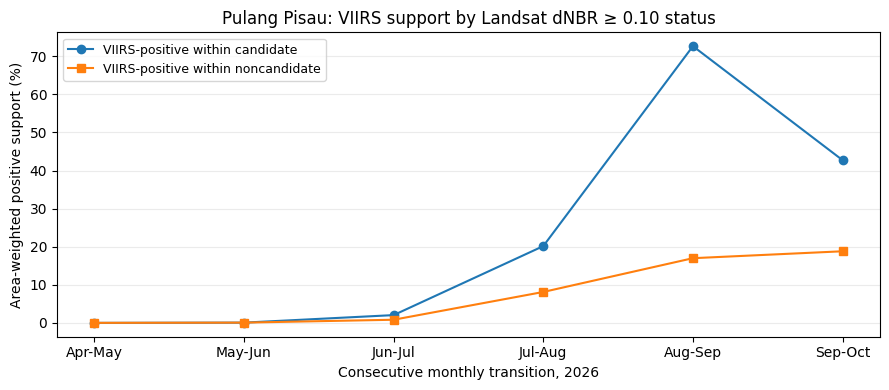

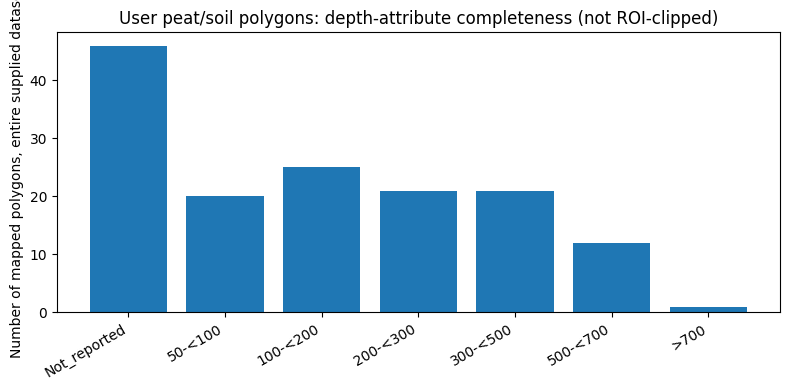

In [ ]:
fig,ax=plt.subplots(figsize=(9,4))
x=np.arange(len(q))
ax.plot(x,q['p_viirs_given_candidate_pct'],marker='o',label='VIIRS-positive within candidate')
ax.plot(x,q['p_viirs_given_noncandidate_pct'],marker='s',label='VIIRS-positive within noncandidate')
ax.set_xticks(x,q.pair)
ax.set_ylabel('Area-weighted positive support (%)')
ax.set_xlabel('Consecutive monthly transition, 2026')
ax.set_title('Pulang Pisau: VIIRS support by Landsat dNBR ≥ 0.10 status')
ax.grid(axis='y',alpha=.25)
ax.legend(loc='upper left',fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES/'v23_VIIRS_conditional_support_from_v22.png',dpi=220)
plt.show()
fig,ax=plt.subplots(figsize=(8,4))
order=['Not_reported','50-<100','100-<200','200-<300','300-<500','500-<700','>700']
counts=peat_attributes.depth_class_cm.value_counts().reindex(order,fill_value=0)
ax.bar(range(len(order)),counts.values)
ax.set_xticks(range(len(order)),order,rotation=30,ha='right')
ax.set_ylabel('Number of mapped polygons, entire supplied dataset')
ax.set_title('User peat/soil polygons: depth-attribute completeness (not ROI-clipped)')
fig.tight_layout()
fig.savefig(FIGURES/'v23_peat_depth_attribute_count.png',dpi=220)
plt.show()

In [ ]:
RUN_EE = True               # User sets True in authenticated Google Colab
EE_PROJECT_ID = 'ee-butarbutarernie'  # from the existing user v22 notebook
PEAT_ASSET_ID = ''          # e.g. projects/ee-butarbutarernie/assets/peat_soil_146
YEAR = 2026
MONTHS = list(range(4,11))
PAIRS = list(range(5,11))
S2_GRID_M = 500
OVERLAP_SCALE_M = 60
CRS = 'EPSG:3857'          # reproduce v22 analytic grid, area calculated using pixelArea()
S2_MIN_VALID_OBS = 2
S2_CLEAR_THRESHOLD = 0.60
S2_ALLOWED_SCL = (4,5,7) # exact legacy mask; class 7 is unclassified
DNBR_MIN = 0.10
VIIRS_CONFIDENCE_MIN = 1
DW_BASELINE_START, DW_BASELINE_END = '2025-01-01','2026-01-01'
DW_TOP1_MIN = 0.50
DW_MIN_OBS = 2
RUN_LANDSAT_VIIRS_STRATA = True
# A one-month diagnostic can precede full six-pair run, but results must be labelled partial.
STRATA_PAIR_MONTHS = list(PAIRS)
RUN_DEPTH_LULC_CROSSTAB = True
CROSS_PAIR_MONTHS = [9]     # Aug–Sep only, explicit sensitivity / separate output
CROSS_LULC_CLASSES = [1,3,4,5,7] # trees, flooded vegetation, crops, shrub, bare

EE_OUTPUT = ROOT/'GEE_v23_Output'
EE_OUTPUT.mkdir(parents=True,exist_ok=True)
print('EE extraction enabled:',RUN_EE, '| Peat asset supplied:', bool(PEAT_ASSET_ID))

EE extraction enabled: True | Peat asset supplied: False


## 3. Live ROI and observation-support reproducibility

Provincial and Pulang Pisau geometries are explicitly recovered from `FAO/GAUL/2015/level1` and `/level2`, matching v22; these are not official 2026 boundaries. Geographic reductions use `ee.Image.pixelArea()` rather than assuming every EPSG:3857 pixel has a constant ground area.

In [ ]:
if RUN_EE:
    try:
        import ee
    except ImportError as exc:
        raise ImportError('Install earthengine-api in Colab: %pip -q install earthengine-api') from exc
    try:
        ee.Initialize(project=EE_PROJECT_ID)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=EE_PROJECT_ID)
    g1=ee.FeatureCollection('FAO/GAUL/2015/level1')
    g2=ee.FeatureCollection('FAO/GAUL/2015/level2')
    prov=g1.filter(ee.Filter.eq('ADM0_NAME','Indonesia')).filter(ee.Filter.eq('ADM1_NAME','Kalimantan Tengah'))
    assert prov.size().getInfo()==1
    ROI=prov.geometry()
    districts=g2.filter(ee.Filter.eq('ADM0_NAME','Indonesia')).filter(ee.Filter.eq('ADM1_NAME','Kalimantan Tengah'))
    names=districts.aggregate_array('ADM2_NAME').getInfo()
    norm=lambda s: ''.join(x for x in str(s).casefold() if x.isalnum())
    matches=[name for name in names if norm(name)==norm('Pulang Pisau')]
    assert len(matches)==1, f'Pulang Pisau not uniquely found: {matches}'
    DETAIL_ROI=districts.filter(ee.Filter.eq('ADM2_NAME',matches[0])).geometry()
    P_AREA_HA=float(ROI.area(maxError=100).divide(1e4).getInfo())
    PP_AREA_HA=float(DETAIL_ROI.area(maxError=100).divide(1e4).getInfo())
    print('EE ROI province ha:',round(P_AREA_HA),'| Pulang Pisau ha:',round(PP_AREA_HA))
    # Reconcile to original v22 Pulang Pisau administrative ROI (~971,645.5 ha).
    if abs(PP_AREA_HA-971645.509)/971645.509 > 0.02:
        raise RuntimeError('Pulang Pisau GAUL boundary area differs by >2% from v22; investigate before overlay')

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)
/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


EE ROI province ha: 15437225 | Pulang Pisau ha: 971646


In [ ]:
S2_BANDS=['NDVI','NBR','NBR2']

def area_weighted_means(three_band_img, region, scale, label):
    """One server reduction for three index weighted means and each exact eligible area."""
    area_ha=ee.Image.pixelArea().divide(1e4)
    images=[]
    for band in S2_BANDS:
        idx=three_band_img.select(band)
        band_area=area_ha.updateMask(idx.mask()).rename(f'{band}_eligible_ha')
        images.extend([idx.multiply(band_area).rename(f'{band}_weighted_sum'),band_area])
    vals=ee.Image.cat(images).reduceRegion(reducer=ee.Reducer.sum(),geometry=region,
        crs=CRS,scale=scale,maxPixels=int(1e10),tileScale=8).getInfo()
    row={'label':label}
    for band in S2_BANDS:
        total=vals.get(f'{band}_eligible_ha')
        numerator=vals.get(f'{band}_weighted_sum')
        row[band+'_eligible_ha']=float(total) if total is not None else 0.0
        row[band+'_mean']=(float(numerator)/float(total)
            if numerator is not None and total is not None and float(total)>0 else np.nan)
    return row

if RUN_EE:
    s2=(ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterBounds(ROI).filterDate('2026-04-01','2026-11-01')
        .filter(ee.Filter.lte('CLOUDY_PIXEL_PERCENTAGE',90)))
    cs=ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
    s2_linked=s2.linkCollection(cs,['cs_cdf'])
    def s2_indices(image):
        scl=image.select('SCL')
        good=scl.eq(4).Or(scl.eq(5)).Or(scl.eq(7))
        good=good.And(image.select('cs_cdf').gte(S2_CLEAR_THRESHOLD))
        # Legacy normalizedDifference masks negative reflective inputs automatically.
        r=image.select(['B4','B8','B11','B12']).multiply(0.0001)
        ndvi=r.normalizedDifference(['B8','B4']).rename('NDVI')
        nbr=r.normalizedDifference(['B8','B12']).rename('NBR')
        nbr2=r.normalizedDifference(['B11','B12']).rename('NBR2')
        return ee.Image.cat([ndvi,nbr,nbr2]).updateMask(good).copyProperties(image,['system:time_start'])
    s2_qc=s2_linked.map(s2_indices)
    S2_MONTHLY={}
    S2_MONTHLY_OBS={}
    for m in MONTHS:
        st=ee.Date.fromYMD(YEAR,m,1);ed=st.advance(1,'month')
        count=int(s2.filterDate(st,ed).size().getInfo())
        if count<=0:raise RuntimeError(f'No S2 scenes in month {m:02d}')
        col=s2_qc.filterDate(st,ed)
        # NDVI observation counting follows the archived v07 convention.
        n=col.select('NDVI').count().unmask(0).rename('n_obs')
        S2_MONTHLY_OBS[m]=n
        S2_MONTHLY[m]=col.median().select(S2_BANDS).updateMask(n.gte(S2_MIN_VALID_OBS)).clip(ROI)
        print(calendar.month_abbr[m],'S2 scene granules=',count)

Apr S2 scene granules= 276
May S2 scene granules= 263
Jun S2 scene granules= 278
Jul S2 scene granules= 328
Aug S2 scene granules= 318
Sep S2 scene granules= 179
Oct S2 scene granules= 107


In [ ]:
if RUN_EE:
    # A conservative common 3-index mask ensures the same pixels across indices.
    triple_masks={m:S2_MONTHLY[m].mask().reduce(ee.Reducer.min()).gt(0).unmask(0)
                  for m in MONTHS}
    common7=ee.Image.constant(1).toByte().clip(ROI)
    for m in MONTHS: common7=common7.And(triple_masks[m])
    month_rows=[]
    for m in MONTHS:
        monthly=area_weighted_means(S2_MONTHLY[m],ROI,S2_GRID_M,'native')
        fixed=area_weighted_means(S2_MONTHLY[m].updateMask(common7),ROI,S2_GRID_M,'fixed7')
        row={'year':YEAR,'month':m}
        for bi in S2_BANDS:
            row[f'{bi}_native_mean']=monthly[f'{bi}_mean']
            row[f'{bi}_native_eligible_ha']=monthly[f'{bi}_eligible_ha']
            row[f'{bi}_fixed7_mean']=fixed[f'{bi}_mean']
            row[f'{bi}_fixed7_eligible_ha']=fixed[f'{bi}_eligible_ha']
        row['fixed7_coverage_pct_of_admin']=100*fixed['NDVI_eligible_ha']/P_AREA_HA
        row['native_coverage_pct_of_admin']=100*monthly['NDVI_eligible_ha']/P_AREA_HA
        month_rows.append(row)
        pd.DataFrame(month_rows).to_csv(EE_OUTPUT/'S2_2026_AprOct_Monthly_Native_and_Fixed7_v23.csv',index=False)
        print(f'Fixed support month {m:02d}: native cover={row["native_coverage_pct_of_admin"]:.2f}% fixed7={row["fixed7_coverage_pct_of_admin"]:.2f}%')
    monthly_q=pd.DataFrame(month_rows)
    pair_rows=[]
    for m in PAIRS:
        mask=triple_masks[m-1].And(triple_masks[m])
        p0=area_weighted_means(S2_MONTHLY[m-1].updateMask(mask),ROI,S2_GRID_M,'paired_tminus1')
        p1=area_weighted_means(S2_MONTHLY[m].updateMask(mask),ROI,S2_GRID_M,'paired_t')
        row={'year':YEAR,'month_t':m,'pair':f'{calendar.month_abbr[m-1]}-{calendar.month_abbr[m]}' }
        for b in S2_BANDS:
            base_native=monthly_q.set_index('month')
            naive=base_native.loc[m,f'{b}_native_mean']-base_native.loc[m-1,f'{b}_native_mean']
            paired=p1[f'{b}_mean']-p0[f'{b}_mean']
            row[f'{b}_native_delta']=naive
            row[f'{b}_paired_delta']=paired
            row[f'{b}_delta_support_discrepancy']=naive-paired
            row[f'{b}_paired_eligible_ha']=p1[f'{b}_eligible_ha']
        row['paired_coverage_pct_admin']=100*p1['NDVI_eligible_ha']/P_AREA_HA
        pair_rows.append(row)
        pd.DataFrame(pair_rows).to_csv(EE_OUTPUT/'S2_2026_SixPairs_Support_Composition_Discrepancy_v23.csv',index=False)
        print(row['pair'],'paired NDVI delta=',round(row['NDVI_paired_delta'],4),
              '| naive delta=',round(row['NDVI_native_delta'],4))
    # Do not overwrite original v11 statistics; export a comparison to detect methodology drift.
    baseline=s2_v07.set_index('month')
    checks=[]
    for _,r in monthly_q.iterrows():
        m=int(r.month)
        checks.append({'month':m,'original_v07_NDVI_mean':float(baseline.loc[m,'NDVI_mean']),
            'new_v23_NDVI_native_mean':r.NDVI_native_mean,
            'delta_NDVI_mean':r.NDVI_native_mean-float(baseline.loc[m,'NDVI_mean']),
            'original_v07_valid_pct':float(baseline.loc[m,'valid_coverage_pct_500m']),
            'new_v23_coverage_pct':r.native_coverage_pct_of_admin})
    pd.DataFrame(checks).to_csv(EE_OUTPUT/'S2_v23_vs_v07_Native_Baseline_Reconciliation.csv',index=False)
    print('S2 outputs saved:',EE_OUTPUT)

Fixed support month 04: native cover=70.10% fixed7=5.40%
Fixed support month 05: native cover=48.41% fixed7=5.40%
Fixed support month 06: native cover=54.20% fixed7=5.40%
Fixed support month 07: native cover=69.82% fixed7=5.40%
Fixed support month 08: native cover=77.17% fixed7=5.40%
Fixed support month 09: native cover=40.84% fixed7=5.40%
Fixed support month 10: native cover=13.85% fixed7=5.40%
Apr-May paired NDVI delta= -0.01 | naive delta= -0.0135
May-Jun paired NDVI delta= 0.0065 | naive delta= 0.0037
Jun-Jul paired NDVI delta= 0.0041 | naive delta= -0.001
Jul-Aug paired NDVI delta= -0.0708 | naive delta= -0.0753
Aug-Sep paired NDVI delta= -0.1509 | naive delta= -0.1435
Sep-Oct paired NDVI delta= -0.0874 | naive delta= -0.0625
S2 outputs saved: /content/CKPP_v23_Analysis_20261114/GEE_v23_Output


In [ ]:
DW_NAMES=['water','trees','grass','flooded_vegetation','crops','shrub_and_scrub',
          'built','bare','snow_and_ice']
DEPTH_CLASSES={0:'Depth not reported (mapped Organosol)',1:'50–<100 cm',2:'100–<200 cm',
               3:'200–<300 cm',4:'300–<500 cm',5:'500–<700 cm',6:'>700 cm'}

if RUN_EE:
    dw=(ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(DETAIL_ROI)
        .filterDate(DW_BASELINE_START,DW_BASELINE_END))
    n_dw=int(dw.size().getInfo())
    if n_dw<=0: raise RuntimeError('No 2025 Dynamic World classifications for this ROI')
    dw_mean=dw.select(DW_NAMES).mean().clip(DETAIL_ROI)
    dw_top1=dw_mean.reduce(ee.Reducer.max()).rename('dw_top1_mean_probability')
    dw_obs_count=dw.select('label').count().rename('dw_obs_count')
    # argmax over the NINE class bands, preserving the ordering in DW_NAMES.
    DW_LABEL_10=(dw_mean.toArray().arrayArgmax().arrayGet([0]).rename('lulc').toInt16()
        .updateMask(dw_top1.gte(DW_TOP1_MIN).And(dw_obs_count.gte(DW_MIN_OBS))))
    # Collection composites lack a meaningful default projection. Compute the
    # categorical mode of eligible 10 m classes before evaluating 60 m strata,
    # rather than nearest-neighbour sampling one 10 m class for a 60 m cell.
    DW_LABEL=(DW_LABEL_10.setDefaultProjection(ee.Projection(CRS).atScale(10))
        .reduceResolution(reducer=ee.Reducer.mode(),bestEffort=False,maxPixels=256)
        .reproject(crs=CRS,scale=OVERLAP_SCALE_M).rename('lulc_majority_60m'))
    print('DW 2025 image assets:',n_dw,'| classes:',dict(enumerate(DW_NAMES)))
    PEAT_DEPTH=None
    if PEAT_ASSET_ID.strip():
        soil=ee.FeatureCollection(PEAT_ASSET_ID).filterBounds(DETAIL_ROI)
        n_soil=int(soil.size().getInfo())
        if n_soil<1:raise RuntimeError('Peat asset has no polygons overlapping original GAUL Pulang Pisau. Check CRS!')
        available=soil.first().propertyNames().getInfo()
        if 'dclass' not in available:raise RuntimeError('Peat asset lacks `dclass`; use supplied upload ZIP')
        PEAT_DEPTH=ee.Image().toInt16().paint(soil,'dclass').rename('peat_depth_code').clip(DETAIL_ROI)
        print('Peat polygons intersecting Pulang Pisau:',n_soil)
    else:
        warnings.warn('PEAT_ASSET_ID not supplied: peat-depth and peat×LULC results will NOT be produced.')

DW 2025 image assets: 177 | classes: {0: 'water', 1: 'trees', 2: 'grass', 3: 'flooded_vegetation', 4: 'crops', 5: 'shrub_and_scrub', 6: 'built', 7: 'bare', 8: 'snow_and_ice'}


/tmp/ipykernel_897/895715614.py:34: UserWarning: PEAT_ASSET_ID not supplied: peat-depth and peat×LULC results will NOT be produced.
  warnings.warn('PEAT_ASSET_ID not supplied: peat-depth and peat×LULC results will NOT be produced.')


In [ ]:
if RUN_EE:
    l8=ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
    l9=ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
    ls_raw=(l8.filterBounds(DETAIL_ROI).filterDate('2026-04-01','2026-11-01')
            .merge(l9.filterBounds(DETAIL_ROI).filterDate('2026-04-01','2026-11-01')))
    satbits=(1<<4)|(1<<6)|(1<<11)
    def nbr_prepare(img):
        nir=img.select('SR_B5').multiply(0.0000275).add(-0.2)
        swir2=img.select('SR_B7').multiply(0.0000275).add(-0.2)
        mask=(img.select('SR_B5').mask().And(img.select('SR_B7').mask())
            .And(img.select('QA_PIXEL').bitwiseAnd(63).eq(0))
            .And(img.select('QA_RADSAT').bitwiseAnd(satbits).eq(0))
            .And(nir.gt(0)).And(swir2.gt(0)))
        return nir.subtract(swir2).divide(nir.add(swir2)).rename('NBR').updateMask(mask).copyProperties(img,['system:time_start'])
    ls_nbr=ls_raw.map(nbr_prepare)
    LS_MONTHLY={}
    for m in MONTHS:
        st=ee.Date.fromYMD(YEAR,m,1);ed=st.advance(1,'month')
        count=int(ls_raw.filterDate(st,ed).size().getInfo())
        if count<=0:raise RuntimeError(f'No Landsat 8/9 optical granules month {m:02d}')
        this=ls_nbr.filterDate(st,ed)
        n_obs=this.count().unmask(0)
        LS_MONTHLY[m]=this.median().rename('NBR').updateMask(n_obs.gte(2)).clip(DETAIL_ROI)
    VIIRS_DATASETS=['NASA/LANCE/SNPP_VIIRS/C2','NASA/LANCE/NOAA20_VIIRS/C2']
    def viirs_flag(img):
        return (img.select('confidence').gte(VIIRS_CONFIDENCE_MIN).selfMask()
                .rename('fire_flag').toUint8().copyProperties(img,['system:time_start']))
    VIIRS_MONTHLY={}
    for m in MONTHS:
        st=ee.Date.fromYMD(YEAR,m,1);ed=st.advance(1,'month')
        collections=[ee.ImageCollection(d).filterBounds(DETAIL_ROI).filterDate(st,ed)
                     for d in VIIRS_DATASETS]
        ns=[int(c.size().getInfo()) for c in collections]
        if sum(ns)==0:
            warnings.warn(f'No VIIRS source for {m:02d}: no thermal comparison allowed')
            continue
        flags=collections[0].merge(collections[1]).map(viirs_flag)
        VIIRS_MONTHLY[m]=flags.sum().unmask(0).rename('fire_positive_observations').toInt16().clip(DETAIL_ROI)
    DNBR_PAIRS={m:LS_MONTHLY[m-1].subtract(LS_MONTHLY[m]).rename('dNBR')
                .updateMask(LS_MONTHLY[m-1].mask().And(LS_MONTHLY[m].mask()))
                .clip(DETAIL_ROI) for m in PAIRS}
    print('Landsat/VIIRS paired images ready:',len(DNBR_PAIRS),'months')

Landsat/VIIRS paired images ready: 6 months


In [ ]:
def area_by_strata(dnbr,viirs,classes,classification,scale=60):
    """One vectorized GEE reduction for all classes and 5 area measures.

    classification=None means a single overall class. All masks are explicitly
    unmasked as Boolean indicators. For peat, zeros OUTSIDE the vector footprint
    remain unmapped and are NOT included in depth class zero.
    """
    pixel_ha=ee.Image.pixelArea().divide(1e4)
    optical=dnbr.mask().gt(0).unmask(0).toByte()
    candidate=dnbr.gte(DNBR_MIN).unmask(0).And(optical).toByte()
    fire=viirs.gt(0).unmask(0).And(optical).toByte()
    overlap=candidate.And(fire).toByte()
    flags={'A':ee.Image.constant(1).toByte(),'E':optical,'C':candidate,'V':fire,'O':overlap}
    bands=[]
    for c in classes:
        mask=(ee.Image.constant(1).toByte() if classification is None
            else classification.unmask(-999).eq(int(c)).toByte())
        for k,flag in flags.items():
            bands.append(pixel_ha.multiply(mask).multiply(flag).rename(f'{k}_{c}'))
    totals=ee.Image.cat(bands).reduceRegion(reducer=ee.Reducer.sum(),geometry=DETAIL_ROI,
        scale=scale,crs=CRS,maxPixels=int(1e10),tileScale=8).getInfo()
    results=[]
    for c in classes:
        vals={k:float(totals.get(f'{k}_{c}') or 0.) for k in flags}
        A,E,C,V,O=[vals[k] for k in ['A','E','C','V','O']]
        tol=max(0.1,0.0001*max(A,E,1))
        if C>E+tol or V>E+tol or O>min(C,V)+tol:
            raise RuntimeError(f'Area invariant fails class={c}, scale={scale} m: {vals}')
        def div(n,d):return float(n/d) if d>0 else np.nan
        p1=div(O,C);p0=div(V-O,E-C)
        results.append({'class_id':int(c),'mapped_extent_ha':A,'eligible_optical_ha':E,
            'candidate_ha':C,'viirs_positive_eligible_ha':V,'overlap_ha':O,
            'optical_observation_fraction_pct':100*div(E,A),
            'candidate_fraction_eligible_pct':100*div(C,E),
            'viirs_positive_given_candidate_pct':100*p1,
            'viirs_positive_given_noncandidate_pct':100*p0,
            'relative_viirs_concentration':div(p1,p0),'evaluation_scale_m':scale})
    return results

if RUN_EE and RUN_LANDSAT_VIIRS_STRATA:
    reference=pair_v22.set_index('month_t')
    STRATA_CSV=EE_OUTPUT/'PulangPisau_2026_SixPairs_Peat_LULC_Stratified_v23.csv'
    rec=[]
    if STRATA_CSV.exists():
        old=pd.read_csv(STRATA_CSV)
        # Reuse only rows for EXACT source config if columns agree; full rerun by default
        warnings.warn('Prior v23 strata file exists; recomputation will overwrite staged results.')
    for m in STRATA_PAIR_MONTHS:
        if m not in VIIRS_MONTHLY:
            warnings.warn(f'No thermal support month {m:02d}; skipping pair instead of counting zero')
            continue
        dnbr=DNBR_PAIRS[m]
        fire=VIIRS_MONTHLY[m]
        pair=f'{calendar.month_abbr[m-1]}-{calendar.month_abbr[m]}'
        # FIRST independently reproduce the six core v22 quantities.
        overall=area_by_strata(dnbr,fire,[0],None,scale=OVERLAP_SCALE_M)[0]
        r=reference.loc[m]
        checks={'eligible_optical_ha':'paired_eligible_optical_area_ha_60m',
            'candidate_ha':'spectral_candidate_dnbr_ge_0p10_ha_60m',
            'viirs_positive_eligible_ha':'eligible_optical_within_viirs_positive_cells_ha_60m',
            'overlap_ha':'spectral_candidate_cooccurring_viirs_ha_60m'}
        for col,src_col in checks.items():
            expected=float(r[src_col]);received=float(overall[col])
            if expected>1 and abs(received-expected)/expected>0.02:
                raise RuntimeError(f'v23 vs v22 mismatch >2% in {pair} {col}: new {received:.3f}, old {expected:.3f}; do not interpret strata results')
        rec.append(dict(overall,month_t=m,pair=pair,stratum='ALL_valid_ROI',class_name='Entire ROI'))
        # Land-cover-only analysis can run even before the peat asset is uploaded.
        for row in area_by_strata(dnbr,fire,list(range(9)),DW_LABEL,scale=OVERLAP_SCALE_M):
            rec.append(dict(row,month_t=m,pair=pair,stratum='DW_2025',class_name=DW_NAMES[row['class_id']]))
        if PEAT_DEPTH is not None:
            for row in area_by_strata(dnbr,fire,list(range(7)),PEAT_DEPTH,scale=OVERLAP_SCALE_M):
                rec.append(dict(row,month_t=m,pair=pair,stratum='PEAT_SOIL_DEPTH',class_name=DEPTH_CLASSES[row['class_id']]))
        pd.DataFrame(rec).to_csv(STRATA_CSV,index=False)
        print('Saved',pair,'rows',len(rec),'| baseline overlap %',round(overall['viirs_positive_given_candidate_pct'],3))
    print('Stratified outputs:',STRATA_CSV)

Saved Apr-May rows 10 | baseline overlap % 0.0
Saved May-Jun rows 20 | baseline overlap % 0.065
Saved Jun-Jul rows 30 | baseline overlap % 2.043
Saved Jul-Aug rows 40 | baseline overlap % 20.16
Saved Aug-Sep rows 50 | baseline overlap % 72.657
Saved Sep-Oct rows 60 | baseline overlap % 42.725
Stratified outputs: /content/CKPP_v23_Analysis_20261114/GEE_v23_Output/PulangPisau_2026_SixPairs_Peat_LULC_Stratified_v23.csv


In [ ]:
if RUN_EE and RUN_DEPTH_LULC_CROSSTAB:
    if PEAT_DEPTH is None:
        print('CROSS-STRATIFIED BLOCK SKIPPED: upload peat asset and set PEAT_ASSET_ID')
    else:
        product=PEAT_DEPTH.multiply(100).add(DW_LABEL).rename('peat_depth_x_lulc')
        crosscodes=[p*100+l for p in range(7) for l in CROSS_LULC_CLASSES]
        rows=[]
        for m in CROSS_PAIR_MONTHS:
            if m not in VIIRS_MONTHLY:
                warnings.warn(f'No VIIRS support in {m}; skipping')
                continue
            blocks=area_by_strata(DNBR_PAIRS[m],VIIRS_MONTHLY[m],crosscodes,
                                  product,scale=OVERLAP_SCALE_M)
            for a in blocks:
                code_id=a['class_id'];p=code_id//100;l=code_id%100
                rows.append(dict(a,month_t=m,peat_depth=DEPTH_CLASSES[p],
                    landcover=DW_NAMES[l],pair=f'{calendar.month_abbr[m-1]}-{calendar.month_abbr[m]}'))
        if rows:
            path=EE_OUTPUT/'PulangPisau_2026_AugSep_PeatDepth_x_DW2025_v23.csv'
            pd.DataFrame(rows).to_csv(path,index=False)
            print('Cross-stratified support:',path)

if RUN_EE:
    month=9
    if month in VIIRS_MONTHLY:
        rows=[]
        for cell_size in (60,120,375):
            a=area_by_strata(DNBR_PAIRS[month],VIIRS_MONTHLY[month],[0],None,
                             scale=cell_size)[0]
            rows.append(dict(a,month_t=month,grid_definition='EPSG3857_sampling'))
        grid_path=EE_OUTPUT/'PulangPisau_2026_AugSep_GridScale_60_120_375_Sensitivity_v23.csv'
        pd.DataFrame(rows).to_csv(grid_path,index=False)
        print('Grid sensitivity saved:',grid_path)

CROSS-STRATIFIED BLOCK SKIPPED: upload peat asset and set PEAT_ASSET_ID
Grid sensitivity saved: /content/CKPP_v23_Analysis_20261114/GEE_v23_Output/PulangPisau_2026_AugSep_GridScale_60_120_375_Sensitivity_v23.csv


In [ ]:

from pathlib import Path
from zipfile import ZipFile
import os

# 1. Periksa konfigurasi runtime
print("Current directory:", Path.cwd())
print("ROOT:", globals().get("ROOT", "Not defined"))
print("EE_OUTPUT:", globals().get("EE_OUTPUT", "Not defined"))
print("RUN_EE:", globals().get("RUN_EE", "Not defined"))

# 2. Cari folder GEE secara otomatis
candidates = []

if "EE_OUTPUT" in globals():
    candidates.append(Path(EE_OUTPUT))

if "ROOT" in globals():
    candidates.append(Path(ROOT) / "GEE_v23_Output")

candidates.append(Path("/content/GEE_v23_Output"))

# Cari di /content, kecuali Google Drive dan cache
for root, dirs, _ in os.walk("/content"):
    dirs[:] = [
        d for d in dirs
        if d not in {"drive", ".cache", ".config"}
    ]
    if "GEE_v23_Output" in dirs:
        candidates.append(Path(root) / "GEE_v23_Output")

# 3. Periksa hasil CSV
found = False

for folder in dict.fromkeys(candidates):
    if not folder.is_dir():
        continue

    csv_files = sorted(folder.glob("*.csv"))

    print("\nFolder ditemukan:", folder)
    print("Jumlah CSV:", len(csv_files))

    for f in csv_files:
        print(" -", f.name)

    if csv_files:
        found = True
        zip_path = Path("/content/GEE_v23_Output.zip")

        with ZipFile(zip_path, "w") as z:
            for f in csv_files:
                z.write(f, arcname=f.name)

        print("\nZIP berhasil dibuat:", zip_path)

        from google.colab import files
        files.download(str(zip_path))
        break

if not found:
    print("\nSTATUS: GEE_OUTPUT_NOT_FOUND")
    print("Belum ada CSV GEE v23 yang ditemukan.")
    print("Jalankan pengolahan GEE pada notebook v23.1.")


Current directory: /content
ROOT: /content/CKPP_v23_Analysis_20261114
EE_OUTPUT: /content/CKPP_v23_Analysis_20261114/GEE_v23_Output
RUN_EE: True

Folder ditemukan: /content/CKPP_v23_Analysis_20261114/GEE_v23_Output
Jumlah CSV: 5
 - PulangPisau_2026_AugSep_GridScale_60_120_375_Sensitivity_v23.csv
 - PulangPisau_2026_SixPairs_Peat_LULC_Stratified_v23.csv
 - S2_2026_AprOct_Monthly_Native_and_Fixed7_v23.csv
 - S2_2026_SixPairs_Support_Composition_Discrepancy_v23.csv
 - S2_v23_vs_v07_Native_Baseline_Reconciliation.csv

ZIP berhasil dibuat: /content/GEE_v23_Output.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import pandas as pd

folder = Path(
    "/content/CKPP_v23_Analysis_20261114/GEE_v23_Output"
)

expected = [
    "S2_2026_AprOct_Monthly_Native_and_Fixed7_v23.csv",
    "S2_2026_SixPairs_Support_Composition_Discrepancy_v23.csv",
    "PulangPisau_2026_SixPairs_Peat_LULC_Stratified_v23.csv",
    "PulangPisau_2026_AugSep_GridScale_60_120_375_Sensitivity_v23.csv",
    "PulangPisau_2026_AugSep_PeatDepth_x_DW2025_v23.csv"
]

print("=== GEE v23 OUTPUT INVENTORY ===")

for name in expected:
    file = folder / name
    status = "AVAILABLE" if file.exists() else "PENDING"
    print(f"{status:10} | {name}")

csv_files = sorted(folder.glob("*.csv"))
print("\nTotal CSV:", len(csv_files))

# Inspect grid sensitivity
grid = folder / expected[3]

if grid.exists():
    df = pd.read_csv(grid)
    print("\n=== GRID SENSITIVITY RESULTS ===")
    print(df.to_string(index=False))

# Package all generated CSV files
if csv_files:
    zip_path = Path("/content/CKPP_GEE_v23_Results.zip")

    with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
        for file in csv_files:
            z.write(file, arcname=file.name)

    print("\nZIP created:", zip_path)

    from google.colab import files
    files.download(str(zip_path))
else:
    print("No CSV results available.")


=== GEE v23 OUTPUT INVENTORY ===
AVAILABLE  | S2_2026_AprOct_Monthly_Native_and_Fixed7_v23.csv
AVAILABLE  | S2_2026_SixPairs_Support_Composition_Discrepancy_v23.csv
AVAILABLE  | PulangPisau_2026_SixPairs_Peat_LULC_Stratified_v23.csv
AVAILABLE  | PulangPisau_2026_AugSep_GridScale_60_120_375_Sensitivity_v23.csv
PENDING    | PulangPisau_2026_AugSep_PeatDepth_x_DW2025_v23.csv

Total CSV: 5

=== GRID SENSITIVITY RESULTS ===
 class_id  mapped_extent_ha  eligible_optical_ha  candidate_ha  viirs_positive_eligible_ha   overlap_ha  optical_observation_fraction_pct  candidate_fraction_eligible_pct  viirs_positive_given_candidate_pct  viirs_positive_given_noncandidate_pct  relative_viirs_concentration  evaluation_scale_m  month_t   grid_definition
        0     967329.414869        939376.845719 128391.617107               231048.001301 93285.134795                         97.110336                        13.667743                           72.656718                              16.987099         

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>